In [1]:
import pairinteraction as pi
from pathlib import Path

pi.Database.initialize_global_database(
    download_missing=False,
    database_dir=Path("~/.cache/pairinteraction/database").expanduser(),
)

In [2]:
N = 80
down = pi.KetAtom("Rb",n=N,l=N-1,j=N-0.5,m=N-0.5)
up = pi.KetAtom("Rb",n=N+1,l=N,j=N+0.5,m=N+0.5)
down.get_matrix_element(up,"electric_dipole",1).to("e * a0")

<Quantity(4539.413157484798, 'elementary_charge * bohr')>

In [3]:
N = 79
down = pi.KetAtom("Sr88_sqdt",n=N,l_ryd=N-1,s=0,j=N-1,m=N-1)
up = pi.KetAtom("Sr88_sqdt",n=N+1,l_ryd=N,s=0,j=N,m=N)
down.get_matrix_element(up,"electric_dipole",1).to("e * a0")

<Quantity(4426.805398225083, 'elementary_charge * bohr')>

In [89]:
import scipy.constants as c
import numpy as np
a0 = c.value("Bohr radius")#4*np.pi*c.epsilon_0*c.hbar**2/(c.m_e*c.e**2)
d = np.array([4426.805398225])*c.e*a0
r0 = np.array([8.15])/10**6
m = 88* c.u
w = 2*np.pi*1000*100
ratio = np.sqrt(c.hbar/2/m/w)**2/r0**2

V = d**2/(4*np.pi*c.epsilon_0*r0**3)#*np.sqrt(c.hbar/2/m/w)**2
V/c.h*ratio , V/c.h*np.sqrt(ratio), np.sqrt(ratio)


(array([305.16573923]), array([103782.97584119]), array([0.00294042]))

In [5]:
7.7/np.sqrt(0.9**2+0.244**2)

np.float64(8.257468803609193)

In [6]:
c.Rydberg*c.c/10**12, c.hbar**2/7/c.u/2/1064**2*10**18/c.h*2500

(3289.8419602499816, 1594321.5329143996)

In [7]:
m = 88* c.u
w = 2*np.pi*1000*100
ratio = np.sqrt(c.hbar/2/m/w)**2/r0**2
ratio

array([8.64608119e-06])

In [8]:
np.sqrt(4*50*1000*c.h/6/c.u)/0.95*10**6/2/np.pi

np.float64(19321.434395485758)

In [9]:
np.sqrt(4*0.7/1000*c.Boltzmann/88/c.u)/1*10**6/2/np.pi

np.float64(81860.59623855379)

In [10]:
ket1 = pi.KetAtom("Rb", n=61, l=0, j=0.5, m=0.5)
ket2 = pi.KetAtom("Rb", n=62, l=1, j=1.5, m=0.5)

c3 = pi.C3(ket1, ket2).get("MHz um^3")
print(f"C3 coefficient between {ket1} and {ket2}: {c3:.3f} MHz um^3")

c6 = pi.C6(ket1, ket1).get("MHz um^6")
print(f"C6 coefficient of {ket1, ket1}: {c6:.3f} MHz um^6")

C3 coefficient between |Rb:61,S_1/2,1/2⟩ and |Rb:62,P_3/2,1/2⟩: -99.956 MHz um^3
C6 coefficient of (KetAtom(Rb:61,S_1/2,1/2), KetAtom(Rb:61,S_1/2,1/2)): -169194.888 MHz um^6


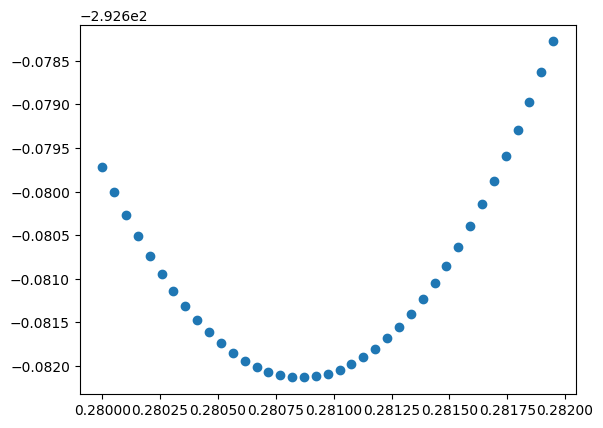

In [11]:
import matplotlib.pyplot as plt
import numpy as np
h =np.sqrt(1-(0.2808)**2)
N = 40
bs = np.linspace(0.28,0.282,N)
ket2 = pi.KetAtom("Rb", n=62, l=1, j=1.5, m=0.5)
c6_coeffs: list[float] = []
for i in range(N):
    c6_obj = pi.C6(ket2, ket2)
    c6_obj.set_diamagnetism_enabled(False)
    c6_obj.set_magnetic_field([0, 0, 20], "gauss")
    theta = np.arctan(h/bs[i])
    c6_obj.set_angle(theta, unit="radian")
    c6_coeffs.append(c6_obj.get("GHz um^6")/(h**2+bs[i]**2)**(6/2))
c6_coeffs = np.array(c6_coeffs)
fig, ax = plt.subplots(1,1)
# ax.scatter(bs,c6_coeffs)
ax.scatter(bs[:-1],(c6_coeffs[1:]-c6_coeffs[:-1])/(bs[1]-bs[0]))
plt.show()

In [12]:
np.arctan(np.sqrt(1-(0.2808)**2)/0.2808), np.pi/2

(np.float64(1.2861687828589614), 1.5707963267948966)

In [13]:
np.arctan(np.sqrt(1-(0.2808)**2)/0.2808), np.pi/2
h0  =  np.sqrt(1-(0.2808)**2)
b0 = 0.2808
aprime = np.array([b0,h0])
hprime = np.array([h0,-b0])

from scipy.differentiate import derivative

def vdw(delta,r):
    # print(r[0])
    c6_obj = pi.C6(ket2, ket2)
    c6_obj.set_diamagnetism_enabled(False)
    c6_obj.set_magnetic_field([0, 0, 20], "gauss")
    theta = np.arctan(r[1]/(r[0]+delta))
    c6_obj.set_angle(theta, unit="radian")
    return c6_obj.get("GHz um^6")/(r[1]**2+(r[0]+delta)**2)**(6/2)


# def dev1(delta,r):
#     dev = derivative(vdw,0,args=(r+np.array([delta,0]),))
#     return dev.df

# def dev2(r):
#     dev = derivative(dev1,0,args=[r,])
#     return dev.df
def dev2(r,delta):
    v0 = vdw(0,r)
    return ((vdw(delta,r)-v0)+(vdw(-delta,r)-v0))/delta**2

def dev_angle(theta,delta):
    r = np.array([np.cos(theta),np.sin(theta)])
    v0 = vdw(0,r)
    return ((vdw(delta,r)-v0)+(vdw(-delta,r)-v0))/delta**2

from scipy.optimize import root_scalar
res = root_scalar(dev_angle,args=(1e-4,),x0=np.pi/3)
res
# N = 30
# deltas = np.logspace(-4.7,-2,N)
# fig, ax = plt.subplots(1,1)
# for i in range(N):
#     ax.scatter(deltas[i],dev2(hprime+0.5*aprime,deltas[i]),color="0.5")
# ax.set_xscale("log",base=10)
# plt.show()
    

      converged: True
           flag: converged
 function_calls: 12
     iterations: 6
           root: 1.8555057919356375
         method: newton

In [14]:
1/10**6*c.Boltzmann/c.h

20836.619123327575

In [15]:
aprime = np.array([np.cos(res.root),np.sin(res.root)])
hprime = np.array([-aprime[1],aprime[0]])
dev2(1.5*aprime+hprime*0.4,1e-4)

np.float64(36.464937913649464)

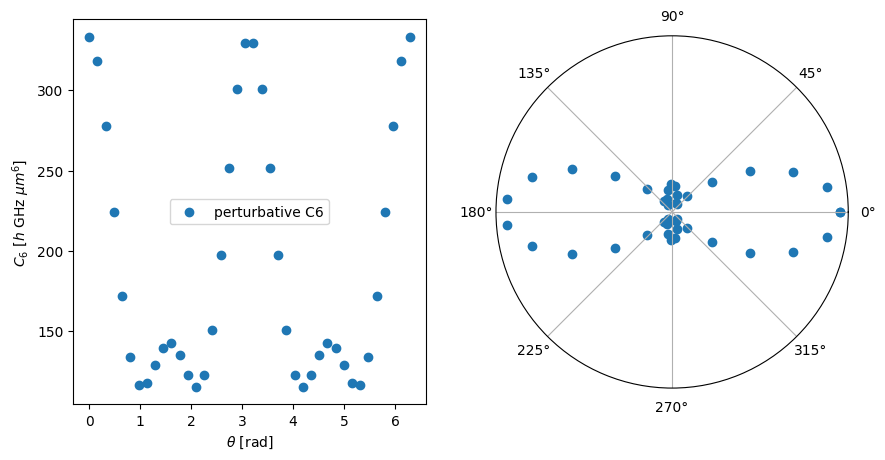

In [16]:
# Calculate C6 coefficients for different angles
ket2 = pi.KetAtom("Rb", n=62, l=1, j=1.5, m=0.5)
c6_coeffs: list[float] = []
thetas = np.linspace(0, 2 * np.pi, 40)
for theta in thetas:
    c6_obj = pi.C6(ket2, ket2)
    c6_obj.set_diamagnetism_enabled(False)
    c6_obj.set_magnetic_field([0, 0, 20], "gauss")
    c6_obj.set_angle(theta, unit="radian")
    c6_coeffs.append(c6_obj.get("GHz um^6"))

# Plot the results
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

axs[1].remove()
axs[1] = fig.add_subplot(1, 2, 2, projection="polar")
# set the radial limits to 0 to the maximum negative value of c6_coeffs and add ticks
# axs[1].set_ylim(0, min(c6_coeffs) * 1.1)
axs[1].set_yticks(np.arange(0, min(c6_coeffs) * 1.1, -25))

for ax in axs:
    ax.scatter(thetas, c6_coeffs, label="perturbative C6")

axs[0].legend()
axs[0].set_xlabel(r"$\theta$ [rad]")
axs[0].set_ylabel(r"$C_6$ [$h$ GHz $\mu m^6$]")

plt.show()

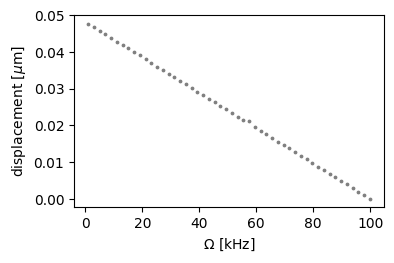

In [ ]:
wl = 10
Omegas = np.linspace(1,50,N)
Omega = Omegas[20]
w = 100 *2*np.pi*1000
delta = 100 
m = 87* c.u
x0 = 1/10**6
lam = np.sqrt(c.hbar/2*w**3*m*x0**2)/c.hbar
t = np.linspace(0,2,10000)
# nmean = lam*((wl*np.sin(wl*t)+delta*np.sin(delta*t))**2+delta**2*(np.cos(wl*t)-np.cos(delta*t))**2)/(wl**2-delta**2)**2
nmean =  lam**2*((Omega-w*np.sin(w*t)*np.sin(Omega*t)-Omega*np.cos(w*t)*np.cos(Omega*t))**2+(w*np.cos(w*t)*np.sin(Omega*t)-Omega*np.sin(w*t)*np.cos(Omega*t))**2)/(w**2-Omega**2)**2
def n_mean(t,Omega):
    return lam**2*((Omega-w*np.sin(w*t)*np.sin(Omega*t)-Omega*np.cos(w*t)*np.cos(Omega*t))**2+(w*np.cos(w*t)*np.sin(Omega*t)-Omega*np.sin(w*t)*np.cos(Omega*t))**2)/(w**2-Omega**2)**2
from scipy.optimize import minimize_scalar
N = 50
Omegas = np.linspace(1,99.9,N)*2*np.pi*1000
max_nmean = np.zeros(N)
for i in range(N):
    # res = minimize_scalar(n_mean,args=(Omegas[i],),bounds=(0,2),method="bounded")
    max_nmean[i] = np.max(n_mean(t,Omegas[i]))
fig, ax = plt.subplots(1,1,figsize=(4,2.5))
ax.scatter(Omegas/2/np.pi/1000,1/np.sqrt(max_nmean),s=3,color="0.5")
# ax.hlines(2*np.pi/Omegas[-1]*4.2/4*10**6,Omegas[0]/2/np.pi/1000,Omegas[-1]/2/np.pi/1000,color="0.5",linestyle="--")
# ax.scatter(Omegas/2/np.pi/1000,2*np.pi/Omegas*4.2/4*10**2,color="0.5")
# ax.plot(t,nmean)
ax.set_xlabel(r"$\Omega$ [kHz]")
ax.set_ylabel(r"displacement [$\mu$m]")
# plt.savefig("/home//christian/Documents/master/protocol/pictures/"+"necessary_trap_displacement_for_excitation.pdf",bbox_inches='tight')

plt.show()

In [80]:
0.8/650

0.0012307692307692308